# Telecom Customer Churn Prediction Using Machine Learning

## Problem Statement

A telecom company is facing a serious problem with customer churn.
When customers leave the company, the business loses recurring revenue
and has to spend additional money to acquire new customers.

The company wants to identify customers who are likely to leave so that
proactive retention strategies, such as personalized offers, discounts,
and better service plans, can be provided before the customer churns.

As a Data Analyst, the objective is to build a machine learning model
that can analyze customer information and predict whether a customer is
likely to churn or stay.

The model should also provide the probability of churn so that the
company can prioritize high-risk customers for retention campaigns.

## Project Objective

The main objectives of this project are:

- Load and understand the telecom customer dataset.
- Identify important customer attributes related to churn.
- Clean and preprocess the dataset.
- Convert categorical data into numerical form.
- Build a classification model using Logistic Regression.
- Predict the probability of customer churn.
- Classify customers as:
  - Likely to Churn
  - Likely to Stay
- Evaluate the model using appropriate classification metrics.
- Analyze correctly and incorrectly classified customers.
- Interpret the model results from a business perspective.
- Suggest an improvement to make churn prediction more reliable.

## 1. Import Required Libraries

We import the libraries required for:

- Data manipulation
- Data visualization
- Data preprocessing
- Machine learning
- Model evaluation

In [1]:
%pip install scikit-learn pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


### Import the Required Libraries

I imported pandas and NumPy for data work, Matplotlib and Seaborn for visualizations, and scikit-learn tools for splitting, scaling, Logistic Regression, and evaluating the model.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

## 2. Load the Dataset

The dataset used for this project is the Telco Customer Churn dataset.

It contains information about customers, their services,
contract details, payment information, and churn status.

In [4]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Understand the Dataset

Before building the model, we first understand the structure
and characteristics of the dataset.

We will check:

- Number of rows and columns
- Column names
- Data types
- Basic statistical information

In [5]:
df.shape
df.columns
df.describe()
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## 4. Clean the Data

I converted `TotalCharges` to a numeric column. Values that could not be converted were marked as missing, and I removed rows with missing values so the model can use valid numeric input.

In [7]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

df = df.dropna()

## 5. Separate Features and Target

I separated the input features (`X`) from the outcome column (`y`). The customer attributes will be used to predict the `Churn` label.

In [8]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

## 6. Encode Categorical Features

I converted categorical input columns into numeric indicator columns using one-hot encoding. I dropped the first category in each group to reduce redundant features.

In [9]:
X = pd.get_dummies(X, drop_first=True)

## 7. Split Training and Test Data

I split the data into training and test sets, keeping 20% for final evaluation. Stratification preserves the churn/stay proportions in both sets, and the fixed random seed makes the split reproducible.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

## 8. Scale the Features

I standardized the numeric feature columns so they are on comparable scales. I fit the scaler on the training data only, then applied that same transformation to the test data to avoid leaking test-set information.

In [11]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 9. Train the Churn Model

I trained a Logistic Regression classifier on the scaled training data. I then generated predicted churn labels and churn probabilities for the held-out test customers.

In [14]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

## 10. Classify Customers

I used a probability threshold of 0.5 to turn churn probabilities into readable categories: customers at or above the threshold are labelled `Likely to Churn`; the others are labelled `Likely to Stay`. The output previews the first ten predictions.

In [15]:
prediction = np.where(
    y_prob >= 0.5,
    "Likely to Churn",
    "Likely to Stay"
)

prediction[:10]

array(['Likely to Stay', 'Likely to Stay', 'Likely to Stay',
       'Likely to Stay', 'Likely to Stay', 'Likely to Stay',
       'Likely to Stay', 'Likely to Stay', 'Likely to Stay',
       'Likely to Stay'], dtype='<U15')

## 11. Review Customer-Level Predictions

I combined each test customer's actual churn outcome, predicted probability, predicted class, and readable prediction label into one table. This lets me compare predictions with known outcomes and inspect individual risk estimates.

In [16]:
results = pd.DataFrame({
    "Actual Churn": y_test.values,
    "Churn Probability": y_prob,
    "Predicted Churn": y_pred,
    "Prediction": prediction
})

results.head(10)

,Actual Churn,Churn Probability,Predicted Churn,Prediction
0,No,0.001133,No,Likely to Stay
1,No,0.379217,No,Likely to Stay
2,No,0.000383,No,Likely to Stay
3,Yes,0.006039,No,Likely to Stay
4,No,0.008194,No,Likely to Stay
5,Yes,0.136055,No,Likely to Stay
6,No,0.000355,No,Likely to Stay
7,No,0.005123,No,Likely to Stay
8,Yes,0.451942,No,Likely to Stay
9,No,0.000877,No,Likely to Stay


## 12. Visualize the Confusion Matrix

I plotted the confusion matrix to compare actual outcomes with predicted outcomes. The diagonal cells represent correct predictions, while off-diagonal cells show the two types of classification errors.

In [20]:
print("Actual values:", y_test.unique())
print("Predicted values:", np.unique(y_pred))
print(classification_report(y_test, y_pred))

Actual values: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Predicted values: ['No' 'Yes']
              precision    recall  f1-score   support

          No       0.79      0.95      0.86      1033
         Yes       0.70      0.30      0.42       374

    accuracy                           0.78      1407
   macro avg       0.74      0.63      0.64      1407
weighted avg       0.77      0.78      0.75      1407



## 13. Check Classification Metrics by Class

I checked the unique actual and predicted labels, then generated a classification report. It summarizes precision, recall, F1 score, and the number of examples for each class.

In [21]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stay", "Churn"]
))

              precision    recall  f1-score   support

        Stay       0.79      0.95      0.86      1033
       Churn       0.70      0.30      0.42       374

    accuracy                           0.78      1407
   macro avg       0.74      0.63      0.64      1407
weighted avg       0.77      0.78      0.75      1407



## 14. Calculate the Confusion Matrix

I calculated the confusion matrix with the class order `No` (stay), then `Yes` (churn). This fixed order makes it clear how to read true negatives, false positives, false negatives, and true positives.

In [22]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[984  49]
 [261 113]]


## 15. Count Correct and Incorrect Predictions

I unpacked the confusion matrix into TN, FP, FN, and TP counts. These counts show how many customers were correctly identified as staying or churning and how many were misclassified.

In [23]:
tn, fp, fn, tp = cm.ravel()

print("Correctly identified churn customers:", tp)
print("Non-churn customers misclassified as churn:", fp)
print("Churn customers missed:", fn)
print("Correctly identified non-churn customers:", tn)

Correctly identified churn customers: 113
Non-churn customers misclassified as churn: 49
Churn customers missed: 261
Correctly identified non-churn customers: 984


## 16. Plot the Confusion Matrix

I displayed the confusion matrix as a heatmap so the correct predictions and error counts are easier to compare visually.

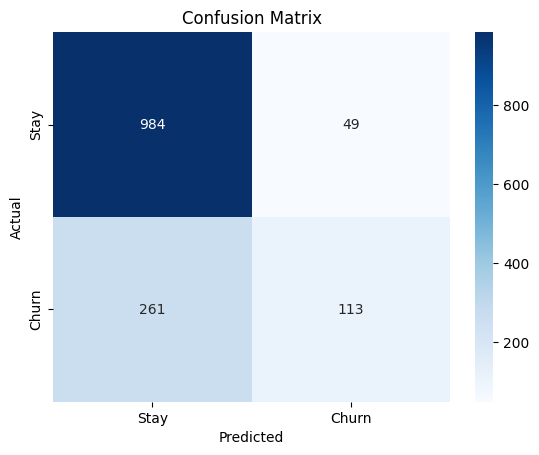

In [24]:
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stay", "Churn"],
    yticklabels=["Stay", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

## 17. Verify the Class Labels

I printed the distinct labels present in the test targets and predictions, then displayed the classification report again with business-friendly class names (`Stay` and `Churn`).

In [26]:
print("Actual values:", y_test.unique())
print("Predicted values:", np.unique(y_pred))

Actual values: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Predicted values: ['No' 'Yes']


## 18. Evaluate Model Performance

I calculated accuracy, churn precision, churn recall, and the churn F1 score. Precision describes how many flagged customers actually churned; recall describes how many actual churners the model found; F1 combines precision and recall.

In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Model Performance")
print("-----------------")

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, pos_label="Yes"))
print("Recall   :", recall_score(y_test, y_pred, pos_label="Yes"))
print("F1 Score :", f1_score(y_test, y_pred, pos_label="Yes"))

Model Performance
-----------------
Accuracy : 0.7796730632551528
Precision: 0.6975308641975309
Recall   : 0.30213903743315507
F1 Score : 0.4216417910447761


## 19. Recheck the Confusion Matrix

I printed the confusion matrix again as a compact numeric summary before interpreting its counts.

In [28]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["No", "Yes"]
)

print(cm)

[[984  49]
 [261 113]]


## 20. Summarize Customer Outcomes

I reported the four confusion-matrix counts in plain language, highlighting correctly identified churners, false alarms, missed churners, and correctly identified customers who stayed.

In [29]:
tn, fp, fn, tp = cm.ravel()

print("Correctly identified churn customers (TP):", tp)
print("Non-churn customers wrongly flagged (FP):", fp)
print("Churn customers missed (FN):", fn)
print("Correctly identified non-churn customers (TN):", tn)

Correctly identified churn customers (TP): 113
Non-churn customers wrongly flagged (FP): 49
Churn customers missed (FN): 261
Correctly identified non-churn customers (TN): 984


## 21. Set the Positive Class

I set `Yes` as the positive label to represent customer churn when interpreting binary classification metrics.

In [30]:
pos_label="Yes"

## Model Evaluation and Business Interpretation

The model was evaluated on **1,407 held-out customers**. With the current classification threshold, it achieved **77.97% accuracy**, **69.75% precision for churn**, **30.21% churn recall**, and an **F1 score of 0.42**. Accuracy alone is not enough to judge this model because most customers in the test set stayed; the low churn recall is an important limitation.

### Confusion matrix results

The matrix uses actual classes as rows and predicted classes as columns, in the order `No` (stay), `Yes` (churn):

| Actual outcome | Predicted stay | Predicted churn |
|---|---:|---:|
| Stay (`No`) | 984 correctly identified | 49 incorrectly flagged (false positives) |
| Churn (`Yes`) | 261 missed (false negatives) | 113 correctly identified |

The model correctly identified **113 churn customers** and **984 non-churn customers**. It wrongly flagged **49 non-churn customers**, and missed **261 customers who actually churned**.

### Business interpretation

A false positive may lead to an unnecessary retention contact or discount, creating campaign cost or giving a loyal customer an avoidable incentive. A false negative means the company misses an at-risk customer and may lose their future revenue. For a retention program, missing likely churners is often more costly, but the right trade-off depends on the cost of an offer, customer lifetime value, and the effectiveness of interventions. Here, the low **30.21% recall** means the current model misses about seven out of every ten churners in this test set, so it should not yet be relied on as the only way to select customers for retention.

### Suggested improvement

Tune the churn-probability decision threshold using a validation set and an explicit business objective (for example, expected retention profit or a minimum acceptable recall), then confirm the selected threshold on a separate test set. A lower threshold may catch more churners, but will usually also increase false positives; compare that trade-off with campaign capacity and cost before deployment.